In [30]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the CSV
file_path = r"C:\Users\Admin\dirty_cafe_sales_experiment.csv"
df_raw = pd.read_csv(file_path)

# Create a separate working copy
df = df_raw.copy(deep=True)

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Original dataset shape: (10020, 8)
Working dataset shape: (10020, 8)

Columns:
['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [31]:
df

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
10015,TXN_1721910,Juice,4,3.0,12.0,Digital Wallet,NaN,2023-03-21
10016,TXN_3826038,Salad,1,5.0,5.0,Cash,Takeaway,2023-10-20
10017,TXN_4428252,Sandwich,3,4.0,12.0,NaN,Takeaway,2023-10-31
10018,TXN_3202346,Salad,2,5.0,10.0,NaN,In-store,2023-11-19


In [32]:

print("Dataset information:")
df.info()

print("\nFirst 10 rows:")
display(df.head(10))

print("\nRandom 10 rows:")
display(df.sample(10, random_state=42))

print("\nMissing values in the original CSV:")
display(df_raw.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate rows:", df_raw.duplicated().sum())
print("Duplicate transaction IDs:",
      df_raw["Transaction ID"].duplicated().sum())

print("\nSummary of all columns:")
display(df_raw.describe(include="all").T)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10020 entries, 0 to 10019
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10020 non-null  object
 1   Item              9686 non-null   object
 2   Quantity          9870 non-null   object
 3   Price Per Unit    9831 non-null   object
 4   Total Spent       9837 non-null   object
 5   Payment Method    7432 non-null   object
 6   Location          6751 non-null   object
 7   Transaction Date  9861 non-null   object
dtypes: object(8)
memory usage: 626.4+ KB

First 10 rows:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31



Random 10 rows:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9419,TXN_3546303,Tea,2,1.5,3.0,Digital Wallet,Takeaway,2023-09-11
8768,TXN_1844925,Tea,5,1.5,7.5,Cash,NaN,2023-10-21
7656,TXN_2673294,Coffee,3,2.0,UNKNOWN,Cash,NaN,2023-11-11
416,TXN_3229758,Coffee,4,2.0,8.0,Cash,Takeaway,UNKNOWN
3710,TXN_2379052,UNKNOWN,1,5.0,5.0,NaN,NaN,2023-02-16
4782,TXN_5067216,UNKNOWN,4,5.0,20.0,NaN,Takeaway,2023-07-24
4094,TXN_6905794,Salad,1,5.0,NaN,Cash,Takeaway,2023-05-31
7551,TXN_1387062,NaN,5,4.0,20.0,Credit Card,NaN,2023-08-22
7735,TXN_1444932,Smoothie,1,4.0,4.0,Cash,In-store,2023-05-24
1393,TXN_2195630,Sandwich,5,ERROR,20.0,Credit Card,Takeaway,2023-03-09



Missing values in the original CSV:


,Missing Count
Transaction ID,0
Item,334
Quantity,150
Price Per Unit,189
Total Spent,183
Payment Method,2588
Location,3269
Transaction Date,159



Duplicate rows: 20
Duplicate transaction IDs: 20

Summary of all columns:


,count,unique,top,freq
Transaction ID,10020,10000,TXN_3432433,2
Item,9686,10,Juice,1175
Quantity,9870,13,5,2013
Price Per Unit,9831,14,3.0,2425
Total Spent,9837,28,6.0,980
Payment Method,7432,5,Digital Wallet,2296
Location,6751,4,Takeaway,3030
Transaction Date,9861,367,UNKNOWN,159


In [12]:

sentinel_values = ["ERROR", "UNKNOWN", "N/A", "NULL", "NONE", ""]

dirty_summary = []

for col in df.columns:
    values = df[col].astype("string").str.strip().str.upper()

    dirty_summary.append({
        "Column": col,
        "Actual Missing": int(df[col].isna().sum()),
        "Error/Unknown/Blank": int(values.isin(sentinel_values).sum()),
        "Unique Values": int(df[col].nunique(dropna=True))
    })

dirty_summary = pd.DataFrame(dirty_summary)
display(dirty_summary)


,Column,Actual Missing,Error/Unknown/Blank,Unique Values
0,Transaction ID,0,0,10000
1,Item,334,636,10
2,Quantity,150,342,13
3,Price Per Unit,189,354,14
4,Total Spent,183,329,28
5,Payment Method,2588,599,5
6,Location,3269,696,4
7,Transaction Date,159,301,367


In [33]:
numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

In [34]:

import pandas as pd
import numpy as np

# Convert numeric columns safely
numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check invalid values before changing them
for col in numeric_cols:
    invalid = df[col].notna() & (df[col] <= 0)
    print(f"{col}: non-positive values = {invalid.sum()}")

# Mark non-positive values as missing
for col in numeric_cols:
    df.loc[df[col] <= 0, col] = np.nan

# Remove exact duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("\nExact duplicate rows removed:", duplicates_before)
print("Rows remaining:", len(df))

# Check duplicate transaction IDs
print(
    "Duplicate transaction IDs remaining:",
    df["Transaction ID"].duplicated().sum()
)

# Verify numeric types
print("\nNumeric column types:")
print(df[numeric_cols].dtypes)


Quantity: non-positive values = 10
Price Per Unit: non-positive values = 10
Total Spent: non-positive values = 10

Exact duplicate rows removed: 20
Rows remaining: 10000
Duplicate transaction IDs remaining: 0

Numeric column types:
Quantity          float64
Price Per Unit    float64
Total Spent       float64
dtype: object


In [16]:

categorical_cols = ["Item", "Payment Method", "Location"]

for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()

# Standardize capitalization for known categories
category_maps = {
    "Item": {
        "coffee": "Coffee", "tea": "Tea", "cake": "Cake",
        "cookie": "Cookie", "salad": "Salad",
        "sandwich": "Sandwich", "smoothie": "Smoothie",
        "juice": "Juice"
    },
    "Payment Method": {
        "cash": "Cash", "credit card": "Credit Card",
        "digital wallet": "Digital Wallet"
    },
    "Location": {
        "in-store": "In-store", "takeaway": "Takeaway"
    }
}

for col, mapping in category_maps.items():
    df[col] = df[col].replace(mapping)

# Calculate expected total only where inputs are available
df["Calculated Total"] = df["Quantity"] * df["Price Per Unit"]

checkable = df["Total Spent"].notna() & df["Calculated Total"].notna()

df["Total Mismatch"] = pd.Series(
    pd.NA, index=df.index, dtype="boolean"
)

df.loc[checkable, "Total Mismatch"] = (
    (df.loc[checkable, "Total Spent"] -
     df.loc[checkable, "Calculated Total"]).abs() > 0.01
)

print("Rows where all three values can be checked:", checkable.sum())
print("Mismatches among checkable rows:",
      int(df.loc[checkable, "Total Mismatch"].sum()))

display(
    df.loc[checkable & df["Total Mismatch"].fillna(False),
           ["Transaction ID", "Quantity", "Price Per Unit",
            "Total Spent", "Calculated Total"]].head(20)
)


Rows where all three values can be checked: 8479
Mismatches among checkable rows: 0


,Transaction ID,Quantity,Price Per Unit,Total Spent,Calculated Total


In [35]:

def iqr_outlier_report(data, columns):
    rows = []

    for col in columns:
        series = data[col].dropna()

        if series.empty:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        mask = data[col].notna() & (
            (data[col] < lower) | (data[col] > upper)
        )

        rows.append({
            "Column": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower Bound": lower,
            "Upper Bound": upper,
            "Outlier Count": int(mask.sum())
        })

    return pd.DataFrame(rows)

outlier_report = iqr_outlier_report(
    df, ["Quantity", "Price Per Unit", "Total Spent"]
)

display(outlier_report)


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Quantity,2.0,4.0,2.0,-1.0,7.0,0
1,Price Per Unit,2.0,4.0,2.0,-1.0,7.0,0
2,Total Spent,4.0,12.0,8.0,-8.0,24.0,258


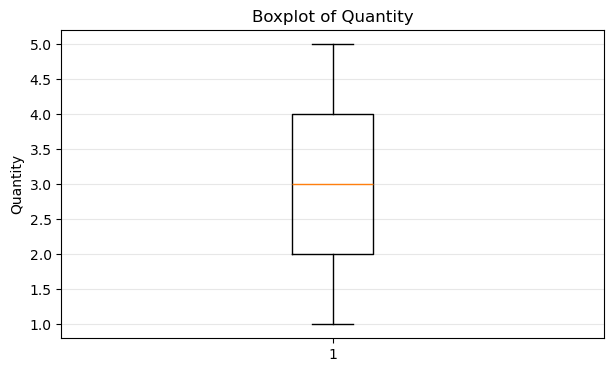

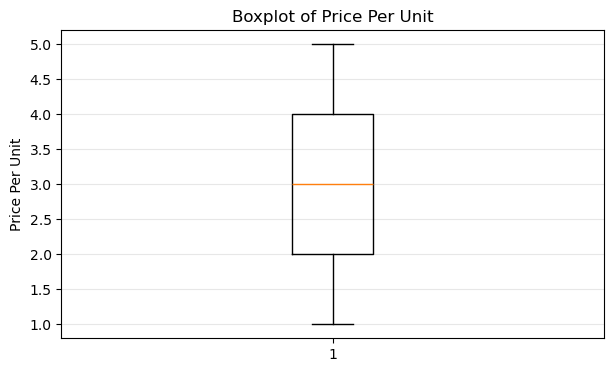

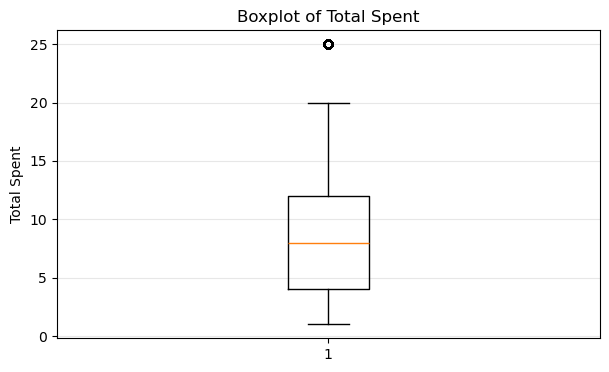

In [36]:

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    plt.figure(figsize=(7, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.grid(axis="y", alpha=0.3)
    plt.show()


In [37]:

df_clean = df.copy()

# Keep the columns needed for ordinary sales analysis.
# Calculated Total and Total Mismatch are retained for validation.
print("Raw rows:", len(df_raw))
print("Cleaned rows:", len(df_clean))

print("\nMissing values in cleaned data:")
display(df_clean.isna().sum().to_frame("Missing Count"))

print("\nMissing percentage:")
display(
    (df_clean.isna().mean() * 100)
    .round(2)
    .to_frame("Missing Percentage")
)

# Save a separate cleaned copy
df_clean.to_csv("dirty_cafe_sales_cleaned.csv", index=False)

print("Saved: dirty_cafe_sales_cleaned.csv")


Raw rows: 10020
Cleaned rows: 10000

Missing values in cleaned data:


,Missing Count
Transaction ID,0
Item,333
Quantity,504
Price Per Unit,558
Total Spent,527
Payment Method,2579
Location,3265
Transaction Date,159



Missing percentage:


,Missing Percentage
Transaction ID,0.00
Item,3.33
Quantity,5.04
Price Per Unit,5.58
Total Spent,5.27
Payment Method,25.79
Location,32.65
Transaction Date,1.59


Saved: dirty_cafe_sales_cleaned.csv


In [38]:

print("NUMERICAL SUMMARY")
display(
    df_clean[["Quantity", "Price Per Unit", "Total Spent"]]
    .describe()
    .round(2)
)

print("\nTotal transactions:", len(df_clean))
print("Transactions with recorded sales totals:",
      df_clean["Total Spent"].count())

print("Total recorded sales:",
      round(df_clean["Total Spent"].sum(), 2))

print("Average recorded transaction value:",
      round(df_clean["Total Spent"].mean(), 2))

print("Median recorded transaction value:",
      round(df_clean["Total Spent"].median(), 2))

print("Most common item:")
print(df_clean["Item"].mode().tolist())


NUMERICAL SUMMARY


,Quantity,Price Per Unit,Total Spent
count,9496.00,9442.00,9473.00
mean,3.03,2.95,8.93
std,1.42,1.28,6.01
min,1.00,1.00,1.00
25%,2.00,2.00,4.00
50%,3.00,3.00,8.00
75%,4.00,4.00,12.00
max,5.00,5.00,25.00



Total transactions: 10000
Transactions with recorded sales totals: 9473
Total recorded sales: 84547.5
Average recorded transaction value: 8.93
Median recorded transaction value: 8.0
Most common item:
['Juice']


,Transactions,Total_Quantity,Total_Recorded_Sales,Average_Transaction
Item,,,,
Salad,1148,3305.0,16565.0,15.14
Sandwich,1131,3237.0,12900.0,12.17
Smoothie,1096,3214.0,12536.0,12.28
Juice,1171,3358.0,9972.0,8.96
Cake,1139,3327.0,9891.0,9.13
Coffee,1165,3368.0,6762.0,6.09
Tea,1089,3154.0,4735.5,4.55
Cookie,1092,3067.0,3058.0,2.96
UNKNOWN,344,937.0,2757.5,8.56


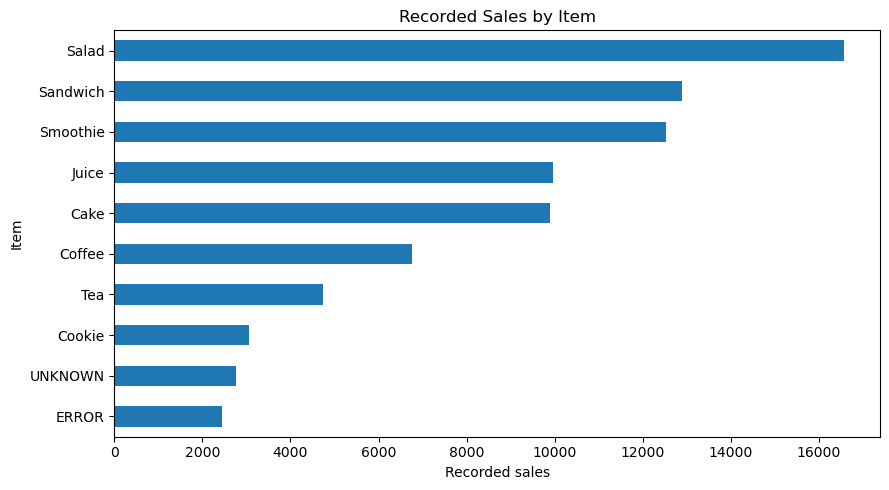

In [39]:

item_analysis = (
    df_clean.dropna(subset=["Item"])
    .groupby("Item")
    .agg(
        Transactions=("Transaction ID", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Recorded_Sales=("Total Spent", "sum"),
        Average_Transaction=("Total Spent", "mean")
    )
    .sort_values("Total_Recorded_Sales", ascending=False)
)

display(item_analysis.round(2))

item_analysis["Total_Recorded_Sales"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Recorded Sales by Item")
plt.xlabel("Recorded sales")
plt.ylabel("Item")
plt.tight_layout()
plt.show()


In [40]:

print("Transactions by payment method:")
display(df_clean["Payment Method"].value_counts(dropna=False))

print("\nRecorded sales by payment method:")
payment_analysis = (
    df_clean.groupby("Payment Method", dropna=False)
    .agg(
        Transactions=("Transaction ID", "count"),
        Recorded_Sales=("Total Spent", "sum"),
        Average_Transaction=("Total Spent", "mean")
    )
    .sort_values("Recorded_Sales", ascending=False)
)
display(payment_analysis.round(2))

print("\nTransactions by location:")
display(df_clean["Location"].value_counts(dropna=False))

print("\nRecorded sales by location:")
location_analysis = (
    df_clean.groupby("Location", dropna=False)
    .agg(
        Transactions=("Transaction ID", "count"),
        Recorded_Sales=("Total Spent", "sum"),
        Average_Transaction=("Total Spent", "mean")
    )
    .sort_values("Recorded_Sales", ascending=False)
)
display(location_analysis.round(2))


Transactions by payment method:


Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64


Recorded sales by payment method:


,Transactions,Recorded_Sales,Average_Transaction
Payment Method,,,
NaN,2579,21434.0,8.78
Credit Card,2273,19559.0,9.03
Digital Wallet,2291,19534.0,8.95
Cash,2258,19269.0,9.07
ERROR,306,2437.5,8.58
UNKNOWN,293,2314.0,8.45



Transactions by location:


Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64


Recorded sales by location:


,Transactions,Recorded_Sales,Average_Transaction
Location,,,
NaN,3265,27848.5,9.00
In-store,3017,25821.0,9.03
Takeaway,3022,25145.5,8.79
ERROR,358,3100.5,9.15
UNKNOWN,338,2632.0,8.25


,Transactions,Recorded_Sales,Average_Transaction
Month,,,
2023-01,818,6807.0,8.87
2023-02,727,6284.0,9.11
2023-03,827,6810.0,8.75
2023-04,774,6714.5,9.31
2023-05,777,6663.0,9.03
2023-06,818,7071.5,9.00
2023-07,791,6556.0,8.78
2023-08,803,6865.0,8.87
2023-09,788,6501.5,8.70


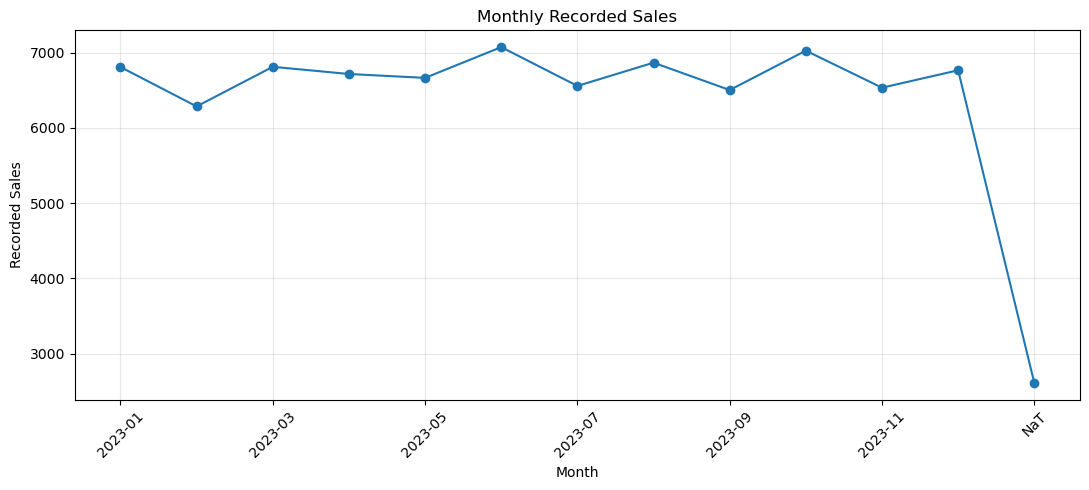

In [44]:

dated_sales = df_clean.dropna(subset=["Transaction Date"]).copy()

# Convert Transaction Date to datetime format
dated_sales["Transaction Date"] = pd.to_datetime(
    dated_sales["Transaction Date"], errors="coerce"
)

# Extract month and year
dated_sales["Month"] = (
    dated_sales["Transaction Date"].dt.to_period("M").astype(str)
)

# Perform monthly analysis
monthly_analysis = (
    dated_sales.groupby("Month")
    .agg(
        Transactions=("Transaction ID", "count"),
        Recorded_Sales=("Total Spent", "sum"),
        Average_Transaction=("Total Spent", "mean")
    )
    .sort_index()
)

display(monthly_analysis.round(2))

# Plot monthly recorded sales
monthly_analysis["Recorded_Sales"].plot(
    figsize=(11, 5), marker="o"
)

plt.title("Monthly Recorded Sales")
plt.xlabel("Month")
plt.ylabel("Recorded Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Quantity,Price Per Unit,Total Spent
Quantity,1.000,0.007,0.705
Price Per Unit,0.007,1.000,0.648
Total Spent,0.705,0.648,1.000


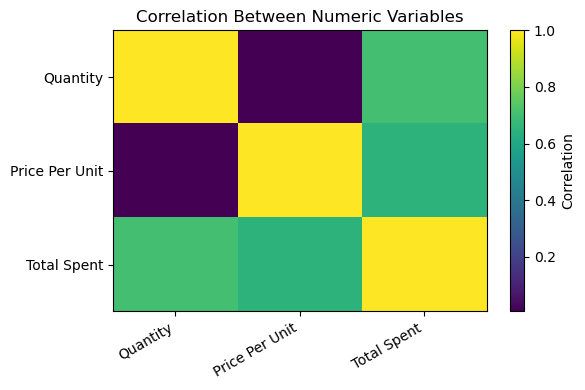

In [45]:

numeric_data = df_clean[
    ["Quantity", "Price Per Unit", "Total Spent"]
]

correlation_matrix = numeric_data.corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(6, 4))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=30, ha="right")
plt.yticks(range(len(correlation_matrix.index)),
           correlation_matrix.index)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()


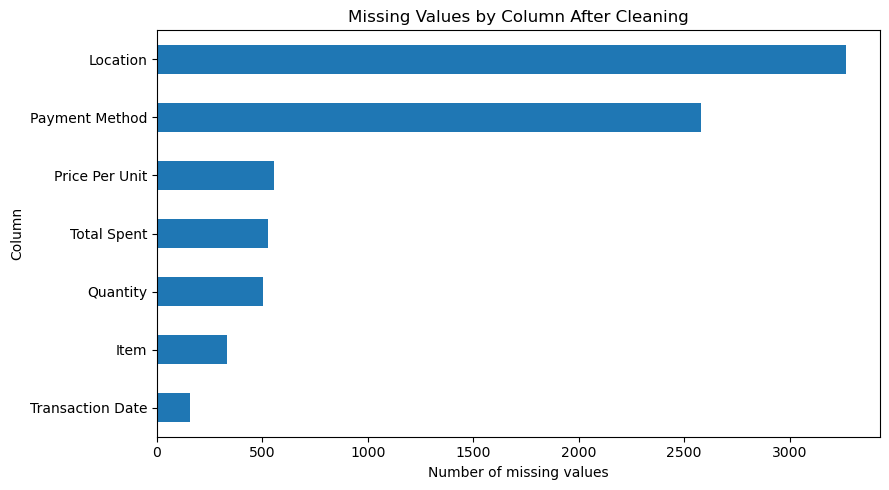

In [48]:

missing_counts = df_clean.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values()

if len(missing_counts) > 0:
    missing_counts.plot(kind="barh", figsize=(9, 5))
    plt.title("Missing Values by Column After Cleaning")
    plt.xlabel("Number of missing values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


In [50]:

import pandas as pd
import numpy as np

# Work on a copy so this section does not change your existing data
ground_truth_df = df.copy(deep=True)

# Convert numeric columns safely
numeric_cols = ["Quantity", "Price Per Unit", "Total Spent"]

for col in numeric_cols:
    ground_truth_df[col] = pd.to_numeric(
        ground_truth_df[col], errors="coerce"
    )

# 1. Total quantity: sum of available recorded quantities
total_quantity = ground_truth_df["Quantity"].sum()

# 2. Total recorded sales: sum of available Total Spent values
total_recorded_sales = ground_truth_df["Total Spent"].sum()

# 3. Calculated line totals: Quantity × Price Per Unit
ground_truth_df["Calculated Total"] = (
    ground_truth_df["Quantity"] *
    ground_truth_df["Price Per Unit"]
)

total_calculated_sales = ground_truth_df["Calculated Total"].sum()

# 4. Calculate totals using only positive values
# This is a separate, explicit rule for ordinary cafe sales.
valid_quantity = ground_truth_df["Quantity"].where(
    ground_truth_df["Quantity"] > 0
)

valid_total_spent = ground_truth_df["Total Spent"].where(
    ground_truth_df["Total Spent"] > 0
)

valid_quantity_price = (
    ground_truth_df["Quantity"].where(
        ground_truth_df["Quantity"] > 0
    ) *
    ground_truth_df["Price Per Unit"].where(
        ground_truth_df["Price Per Unit"] > 0
    )
)

total_positive_quantity = valid_quantity.sum()
total_positive_recorded_sales = valid_total_spent.sum()
total_positive_calculated_sales = valid_quantity_price.sum()

# 5. Count rows and data-quality issues
summary = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total quantity (available values)",
        "Total recorded sales (available values)",
        "Total calculated sales (Quantity × Price Per Unit)",
        "Total positive quantity",
        "Total positive recorded sales",
        "Total positive calculated sales",
        "Missing Quantity values",
        "Missing Price Per Unit values",
        "Missing Total Spent values",
        "Negative Quantity values",
        "Negative Price Per Unit values",
        "Negative Total Spent values",
        "Exact duplicate rows"
    ],
    "Python Ground Truth": [
        len(ground_truth_df),
        total_quantity,
        total_recorded_sales,
        total_calculated_sales,
        total_positive_quantity,
        total_positive_recorded_sales,
        total_positive_calculated_sales,
        ground_truth_df["Quantity"].isna().sum(),
        ground_truth_df["Price Per Unit"].isna().sum(),
        ground_truth_df["Total Spent"].isna().sum(),
        (ground_truth_df["Quantity"] < 0).sum(),
        (ground_truth_df["Price Per Unit"] < 0).sum(),
        (ground_truth_df["Total Spent"] < 0).sum(),
        ground_truth_df.duplicated().sum()
    ]
})

display(summary.round(2))

# Save the reference results
summary.to_csv("python_ground_truth_summary.csv", index=False)

print("Saved: python_ground_truth_summary.csv")


,Metric,Python Ground Truth
0,Total rows,10000.0
1,Total quantity (available values),28763.0
2,Total recorded sales (available values),84547.5
3,Total calculated sales (Quantity × Price Per U...,80064.5
4,Total positive quantity,28763.0
5,Total positive recorded sales,84547.5
6,Total positive calculated sales,80064.5
7,Missing Quantity values,504.0
8,Missing Price Per Unit values,558.0
9,Missing Total Spent values,527.0


Saved: python_ground_truth_summary.csv
